# Is the quantum harmonic oscillator an LC circuit? Yes.

| mass-spring | LC circuit | quantum |
|---|---|---|
| position x | charge Q | operator Q |
| momentum p = m ẋ | flux Φ = L I | [Q, Φ] = iħ |
| mass m | inductance L | |
| spring k | 1/C | |
| ω = √(k/m) | ω = 1/√(LC) | Eₙ = ħω(n + ½) |

Cool a superconducting LC circuit to millikelvin and it *is* a quantum harmonic oscillator. Add a
Josephson junction, a nonlinear inductor, and the levels stop being evenly spaced: that is a
transmon qubit. This notebook covers:

1. The mapping and **symmetry**: no explicit time in the Lagrangian → energy is conserved (Noether)
2. The solution ω = 1/√(LC)
3. Simulation: a symplectic integrator keeps that symmetry; resistance breaks it
4. Quantum levels, zero-point fluctuations, and why it takes a dilution fridge
5. Terahertz: where P = VI and lumped circuits stop working, and Jalali's time stretch
6. Residuals in torch on the CPU and the CUDA GPU (a one-parameter PINN)
7. Compiling every Lean cell

| Label | Meaning |
|---|---|
| **SymPy** | exact computer algebra |
| **Lean** | machine-checked; counts only if `%lean_check` (§7) reports VERIFIED |
| **Numerical** | agreement to a stated tolerance: evidence, not proof |

In [1]:
import sys, time, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, pandas as pd, sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
sp.init_printing(use_unicode=True)
from dgs import lc_oscillator as O
L0, C0 = 10e-9, 100e-15          # 10 nH, 100 fF: a 5 GHz qubit-style resonator

In [2]:
%load_ext dgs.lean_magic
%lean_reset

Lean cells cleared.


In [3]:
%%lean header
/-
The LC circuit as a harmonic oscillator: the machine-checkable pieces. Lean 4 + Mathlib.
Companion to notebooks/lc_quantum_oscillator.ipynb.

What is proved here:
  1. The mapping: the mass-spring energy with m = L, k = 1/C, x = Q, p = Phi is the LC energy
  2. Energy conservation: if Q' = I and L I' = -Q/C then dE/dt = L I I' + Q Q'/C = 0
  3. The solution: Q(t) = Q0 cos(w t) has Q'' = -w^2 Q, so it solves L Q'' + Q/C = 0 when w^2 L C = 1
  4. Quantum ladder: E_(n+1) - E_n = hbar w, and E_0 = hbar w / 2 > 0
  5. Zero-point fluctuations: dQ^2 = hbar/(2Z), dPhi^2 = hbar Z/2  =>  (dQ dPhi)^2 = (hbar/2)^2
  6. Terahertz: the free-space wavelength at 1 THz is under 1 mm; time stretch M > 1 raises bandwidth

Check with (from a Lake project that depends on Mathlib):
    lake env lean LCOscillator.lean
-/
import Mathlib.Analysis.SpecialFunctions.Trigonometric.Deriv
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp

namespace LCOsc

**Lean cell `header`** (collected; compiled by `%lean_check`)
```lean
/-
The LC circuit as a harmonic oscillator: the machine-checkable pieces. Lean 4 + Mathlib.
Companion to notebooks/lc_quantum_oscillator.ipynb.

What is proved here:
  1. The mapping: the mass-spring energy with m = L, k = 1/C, x = Q, p = Phi is the LC energy
  2. Energy conservation: if Q' = I and L I' = -Q/C then dE/dt = L I I' + Q Q'/C = 0
  3. The solution: Q(t) = Q0 cos(w t) has Q'' = -w^2 Q, so it solves L Q'' + Q/C = 0 when w^2 L C = 1
  4. Quantum ladder: E_(n+1) - E_n = hbar w, and E_0 = hbar w / 2 > 0
  5. Zero-point fluctuations: dQ^2 = hbar/(2Z), dPhi^2 = hbar Z/2  =>  (dQ dPhi)^2 = (hbar/2)^2
  6. Terahertz: the free-space wavelength at 1 THz is under 1 mm; time stretch M > 1 raises bandwidth

Check with (from a Lake project that depends on Mathlib):
    lake env lean LCOscillator.lean
-/
import Mathlib.Analysis.SpecialFunctions.Trigonometric.Deriv
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp

namespace LCOsc
```

## 1. The mapping and the symmetry

The LC Lagrangian is ℒ = ½ L Q̇² − Q²/(2C): "kinetic" magnetic energy minus "potential" electric
energy. It has no explicit `t`, so it is the same today and tomorrow. Noether's theorem turns that
time-translation symmetry into a conserved quantity: the energy E = ½ L Q̇² + Q²/(2C).
**(SymPy)**

,quantity,mass-spring,LC circuit,SI unit
0,position,x,charge Q,C
1,momentum,p = m dx/dt,flux Phi = L I,Wb
2,mass (inertia),m,inductance L,H
3,stiffness,k,1/C,1/F
4,kinetic energy,p^2 / 2m,Phi^2 / 2L = L I^2 / 2,J
5,potential energy,k x^2 / 2,Q^2 / 2C,J
6,angular frequency,sqrt(k/m),1/sqrt(LC),rad/s
7,damping,b dx/dt,R I,


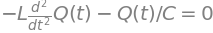

dE/dt on solutions: 0


In [4]:
display(pd.DataFrame(O.MAPPING, columns=["quantity", "mass-spring", "LC circuit", "SI unit"]))
t = sp.symbols("t", real=True)
L, C, w = sp.symbols("L C omega", positive=True)
Q = sp.Function("Q")(t)
Lag = L * Q.diff(t)**2 / 2 - Q**2 / (2 * C)
EL = sp.euler_equations(Lag, Q, t)[0]
display(EL)                                                   # L Q'' + Q/C = 0 (up to sign)
E = Q.diff(t) * sp.diff(Lag, Q.diff(t)) - Lag                 # Noether energy function
display(sp.Eq(sp.Symbol("E"), sp.simplify(E)))
dEdt = sp.diff(E, t).subs(Q.diff(t, 2), sp.solve(EL.lhs, Q.diff(t, 2))[0])
print("dE/dt on solutions:", sp.simplify(dEdt))

In [5]:
%%lean mapping
/-! ## 1. The mapping mass-spring -> LC -/

theorem energy_mapping (L C Q Φ : ℝ) :
    Φ ^ 2 / (2 * L) + (1 / C) * Q ^ 2 / 2 = Φ ^ 2 / (2 * L) + Q ^ 2 / (2 * C) := by
  ring

**Lean cell `mapping`** (collected; compiled by `%lean_check`)
```lean
/-! ## 1. The mapping mass-spring -> LC -/

theorem energy_mapping (L C Q Φ : ℝ) :
    Φ ^ 2 / (2 * L) + (1 / C) * Q ^ 2 / 2 = Φ ^ 2 / (2 * L) + Q ^ 2 / (2 * C) := by
  ring
```

In [6]:
%%lean energy
/-! ## 2. Energy conservation (time-translation symmetry) -/

/-- Qd stands for dQ/dt and Id for dI/dt. -/
theorem energy_rate_zero (L C Q I Qd Id : ℝ) (h1 : Qd = I) (h2 : L * Id = -Q / C) :
    L * I * Id + Q * Qd / C = 0 := by
  rw [h1]
  linear_combination I * h2

**Lean cell `energy`** (collected; compiled by `%lean_check`)
```lean
/-! ## 2. Energy conservation (time-translation symmetry) -/

/-- Qd stands for dQ/dt and Id for dI/dt. -/
theorem energy_rate_zero (L C Q I Qd Id : ℝ) (h1 : Qd = I) (h2 : L * Id = -Q / C) :
    L * I * Id + Q * Qd / C = 0 := by
  rw [h1]
  linear_combination I * h2
```

## 2. The solution: ω = 1/√(LC)  **(SymPy, Lean)**

In [7]:
sol = sp.dsolve(sp.Eq(L * Q.diff(t, 2) + Q / C, 0), Q)
display(sol)
p = O.lc_params(L0, C0)
print(f"L = 10 nH, C = 100 fF:  f0 = {p['f0']/1e9:.3f} GHz,  Z = {p['Z']:.1f} ohm")

L = 10 nH, C = 100 fF:  f0 = 5.033 GHz,  Z = 316.2 ohm


In [8]:
%%lean solution
/-! ## 3. The cosine solves the LC equation -/

theorem hasDerivAt_cos_mul (w Q0 t : ℝ) :
    HasDerivAt (fun t => Q0 * Real.cos (w * t)) (Q0 * (-Real.sin (w * t) * w)) t := by
  have h := ((hasDerivAt_id t).const_mul w).cos
  simpa using h.const_mul Q0

theorem hasDerivAt_sin_mul (w Q0 t : ℝ) :
    HasDerivAt (fun t => Q0 * (-Real.sin (w * t) * w)) (Q0 * (-(Real.cos (w * t) * w) * w)) t := by
  have h := ((hasDerivAt_id t).const_mul w).sin
  have h2 := ((h.neg).mul_const w).const_mul Q0
  simpa using h2

theorem cos_second_deriv (w Q0 t : ℝ) :
    deriv (deriv (fun t => Q0 * Real.cos (w * t))) t = -(w ^ 2) * (Q0 * Real.cos (w * t)) := by
  have hd : deriv (fun t => Q0 * Real.cos (w * t)) = fun t => Q0 * (-Real.sin (w * t) * w) := by
    funext s; exact (hasDerivAt_cos_mul w Q0 s).deriv
  rw [hd, (hasDerivAt_sin_mul w Q0 t).deriv]
  ring

/-- With Q'' = -w^2 Q and w^2 L C = 1, the LC equation L Q'' + Q/C = 0 holds. -/
theorem lc_equation (L C w Q : ℝ) (hC : C ≠ 0) (hw : w ^ 2 * (L * C) = 1) :
    L * (-(w ^ 2) * Q) + Q / C = 0 := by
  have : L * (-(w ^ 2) * Q) + Q / C = Q / C * (1 - w ^ 2 * (L * C)) := by
    field_simp
    ring
  rw [this, hw]
  ring

**Lean cell `solution`** (collected; compiled by `%lean_check`)
```lean
/-! ## 3. The cosine solves the LC equation -/

theorem hasDerivAt_cos_mul (w Q0 t : ℝ) :
    HasDerivAt (fun t => Q0 * Real.cos (w * t)) (Q0 * (-Real.sin (w * t) * w)) t := by
  have h := ((hasDerivAt_id t).const_mul w).cos
  simpa using h.const_mul Q0

theorem hasDerivAt_sin_mul (w Q0 t : ℝ) :
    HasDerivAt (fun t => Q0 * (-Real.sin (w * t) * w)) (Q0 * (-(Real.cos (w * t) * w) * w)) t := by
  have h := ((hasDerivAt_id t).const_mul w).sin
  have h2 := ((h.neg).mul_const w).const_mul Q0
  simpa using h2

theorem cos_second_deriv (w Q0 t : ℝ) :
    deriv (deriv (fun t => Q0 * Real.cos (w * t))) t = -(w ^ 2) * (Q0 * Real.cos (w * t)) := by
  have hd : deriv (fun t => Q0 * Real.cos (w * t)) = fun t => Q0 * (-Real.sin (w * t) * w) := by
    funext s; exact (hasDerivAt_cos_mul w Q0 s).deriv
  rw [hd, (hasDerivAt_sin_mul w Q0 t).deriv]
  ring

/-- With Q'' = -w^2 Q and w^2 L C = 1, the LC equation L Q'' + Q/C = 0 holds. -/
theorem lc_equation (L C w Q : ℝ) (hC : C ≠ 0) (hw : w ^ 2 * (L * C) = 1) :
    L * (-(w ^ 2) * Q) + Q / C = 0 := by
  have : L * (-(w ^ 2) * Q) + Q / C = Q / C * (1 - w ^ 2 * (L * C)) := by
    field_simp
    ring
  rw [this, hw]
  ring
```

## 3. Simulation: keeping the symmetry numerically  **(Numerical)**

Leapfrog is *symplectic*: it preserves the structure of Hamilton's equations, so the energy
error stays bounded forever instead of drifting. A resistor breaks time-reversal symmetry, and
the energy decays as e^(−Rt/L).

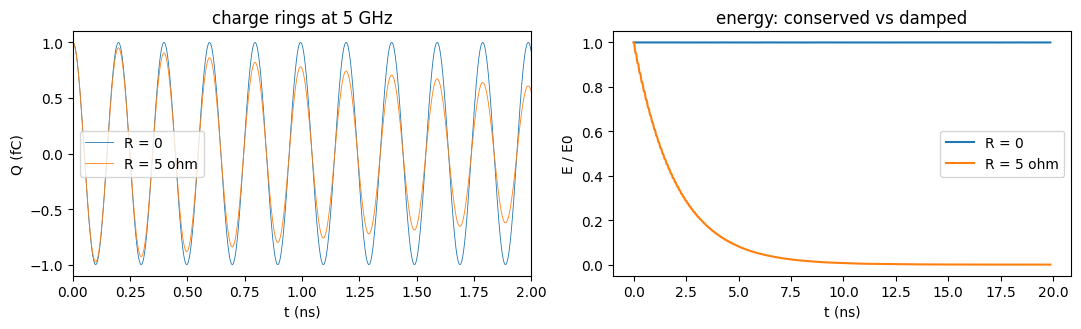

R = 0, 1000 periods: max |E/E0 - 1| = 2.5e-04


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for R, lab in [(0.0, "R = 0"), (5.0, "R = 5 ohm")]:
    s = O.simulate_lc(L0, C0, Q0=1e-15, periods=100, R=R)
    ax[0].plot(s["t"] * 1e9, s["Q"] / 1e-15, lw=0.6, label=lab)
    ax[1].plot(s["t"] * 1e9, s["E"] / s["E"][0], label=lab)
ax[0].set(xlabel="t (ns)", ylabel="Q (fC)", title="charge rings at 5 GHz"); ax[0].set_xlim(0, 2)
ax[1].set(xlabel="t (ns)", ylabel="E / E0", title="energy: conserved vs damped")
for a in ax: a.legend()
plt.tight_layout(); plt.show()
s = O.simulate_lc(L0, C0, Q0=1e-15, periods=1000)
print("R = 0, 1000 periods: max |E/E0 - 1| =", f"{np.max(np.abs(s['E']/s['E'][0]-1)):.1e}")

## 4. Quantum: levels, zero-point, and the fridge

Quantize with [Q, Φ] = iħ and you get Eₙ = ħω(n + ½). Even the ground state has energy ħω/2,
and charge and flux fluctuate with ΔQ·ΔΦ = ħ/2 exactly. At 5 GHz, one quantum is
ħω/k_B ≈ 0.24 K, so you need ~10 mK (a dilution refrigerator) to keep thermal photons out.
**(SymPy, Lean, Numerical)**

E_(n+1) - E_n = hbar*omega


,n,E (ueV),E / k_B (K)
0,0,10.407,0.1208
1,1,31.222,0.3623
2,2,52.036,0.6039
3,3,72.851,0.8454
4,4,93.665,1.0869


zero-point: dQ = 2.55 electrons, dV = 4.08 uV, dQ dPhi / hbar = 0.500


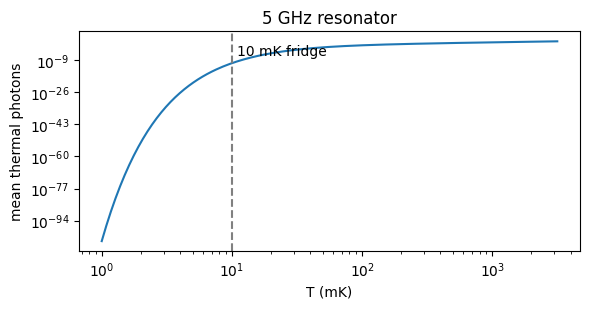

In [10]:
n = sp.symbols("n", integer=True, nonnegative=True); hb = sp.symbols("hbar", positive=True)
En = hb * w * (n + sp.Rational(1, 2))
print("E_(n+1) - E_n =", sp.simplify(En.subs(n, n + 1) - En))
q = O.quantum_levels(L0, C0, 4)
display(pd.DataFrame({"n": q["n"], "E (ueV)": q["E_ueV"].round(3), "E / k_B (K)": q["E_K"].round(4)}))
z = O.zero_point(L0, C0)
print(f"zero-point: dQ = {z['dQ_electrons']:.2f} electrons, dV = {z['dV_V']*1e6:.2f} uV, dQ dPhi / hbar = {z['product_over_hbar']:.3f}")
T = np.logspace(-3, 0.5, 200)
plt.figure(figsize=(6, 3.2)); plt.loglog(T * 1e3, [O.thermal_occupation(L0, C0, x) for x in T])
plt.axvline(10, ls="--", c="gray"); plt.text(11, 1e-6, "10 mK fridge")
plt.xlabel("T (mK)"); plt.ylabel("mean thermal photons"); plt.title("5 GHz resonator"); plt.tight_layout(); plt.show()

In [11]:
%%lean ladder
/-! ## 4. The quantum ladder -/

theorem ladder_spacing (hb w : ℝ) (n : ℕ) :
    hb * w * ((n + 1 : ℕ) + 1 / 2) - hb * w * (n + 1 / 2) = hb * w := by
  push_cast
  ring

theorem zero_point_positive (hb w : ℝ) (hhb : 0 < hb) (hw : 0 < w) :
    0 < hb * w * ((0 : ℕ) + 1 / 2) := by
  push_cast
  positivity

**Lean cell `ladder`** (collected; compiled by `%lean_check`)
```lean
/-! ## 4. The quantum ladder -/

theorem ladder_spacing (hb w : ℝ) (n : ℕ) :
    hb * w * ((n + 1 : ℕ) + 1 / 2) - hb * w * (n + 1 / 2) = hb * w := by
  push_cast
  ring

theorem zero_point_positive (hb w : ℝ) (hhb : 0 < hb) (hw : 0 < w) :
    0 < hb * w * ((0 : ℕ) + 1 / 2) := by
  push_cast
  positivity
```

In [12]:
%%lean zero_point
/-! ## 5. Zero-point fluctuations sit at the uncertainty limit -/

theorem zero_point_product (hb Z dQ dP : ℝ) (hZ : Z ≠ 0)
    (hQ : dQ ^ 2 = hb / (2 * Z)) (hP : dP ^ 2 = hb * Z / 2) :
    (dQ * dP) ^ 2 = (hb / 2) ^ 2 := by
  rw [mul_pow, hQ, hP]
  field_simp

**Lean cell `zero_point`** (collected; compiled by `%lean_check`)
```lean
/-! ## 5. Zero-point fluctuations sit at the uncertainty limit -/

theorem zero_point_product (hb Z dQ dP : ℝ) (hZ : Z ≠ 0)
    (hQ : dQ ^ 2 = hb / (2 * Z)) (hP : dP ^ 2 = hb * Z / 2) :
    (dQ * dP) ^ 2 = (hb / 2) ^ 2 := by
  rw [mul_pow, hQ, hP]
  field_simp
```

## 5. Terahertz: where P = VI stops being enough

P = VI assumes one voltage per node, which needs the circuit to be small compared with the
wavelength (rule of thumb: under λ/10). At 1 THz, λ = 0.3 mm in air. A 1 mm part is then
longer than a wavelength: it's a transmission line or waveguide, and power is the Poynting flux
E × H, not a single V times I. That's why THz electronics is hard, and why Jalali's **photonic time
stretch** helps: slow the signal down optically by a factor M, then digitize it with an ordinary ADC.
**(Numerical, Lean)**

In [13]:
rows = []
for f in [1e6, 1e9, 10e9, 100e9, 1e12, 10e12]:
    r = O.lumped_ok(f, 1e-3)
    rows.append((f"{f:.0e} Hz", f"{r['lambda_m']*1e3:.3g} mm", f"{r['size_over_lambda']:.3g}", "lumped" if r["lumped_ok"] else "distributed (waves)"))
display(pd.DataFrame(rows, columns=["frequency", "wavelength", "1 mm / lambda", "treat a 1 mm part as"]))
ts = O.time_stretch(20e9, 50, 1e-9)
print(f"time stretch M = 50 with a 20 GHz digitizer: effective {ts['effective_bandwidth_Hz']/1e12:.1f} THz, "
      f"captured window {ts['captured_window_s']*1e12:.0f} ps per frame")
print("P = VI averaged over a cycle with V, I 90 degrees apart (pure LC):", round(O.average_power(1.0, 1.0, math.pi/2), 12), "W")

,frequency,wavelength,1 mm / lambda,treat a 1 mm part as
0,1e+06 Hz,3e+05 mm,3.34e-06,lumped
1,1e+09 Hz,300 mm,0.00334,lumped
2,1e+10 Hz,30 mm,0.0334,lumped
3,1e+11 Hz,3 mm,0.334,distributed (waves)
4,1e+12 Hz,0.3 mm,3.34,distributed (waves)
5,1e+13 Hz,0.03 mm,33.4,distributed (waves)


time stretch M = 50 with a 20 GHz digitizer: effective 1.0 THz, captured window 20 ps per frame
P = VI averaged over a cycle with V, I 90 degrees apart (pure LC): 0.0 W


In [14]:
display(pd.DataFrame([(n_, f"${lo:,.0f}", f"${hi:,.0f}") for n_, lo, hi in O.COSTS],
                     columns=["how to look at fast signals", "low", "high"]))
print("Rough 2026 order-of-magnitude ranges, not quotes.")

,how to look at fast signals,low,high
0,simulation on your own laptop / RTX 4060 (this...,$0,$0
1,university lab or shared-facility access,$0,"$5,000"
2,~20-33 GHz real-time oscilloscope,"$100,000","$300,000"
3,50-100 GHz sampling (equivalent-time) scope,"$50,000","$200,000"
4,~100+ GHz real-time oscilloscope (top of the m...,"$1,000,000","$2,000,000"
5,commercial THz time-domain spectroscopy system,"$50,000","$300,000"
6,"DIY time-stretch bench: fiber laser, dispersiv...","$20,000","$100,000"


Rough 2026 order-of-magnitude ranges, not quotes.


In [15]:
%%lean thz
/-! ## 6. Terahertz numbers -/

/-- c / (1 THz) < 1 mm: a millimetre-sized circuit is not lumped at 1 THz. -/
theorem thz_wavelength_sub_mm : (299792458 : ℝ) / 10 ^ 12 < 1 / 1000 := by
  norm_num

theorem stretch_raises_bandwidth (B M : ℝ) (hB : 0 < B) (hM : 1 < M) : B < M * B := by
  nlinarith

**Lean cell `thz`** (collected; compiled by `%lean_check`)
```lean
/-! ## 6. Terahertz numbers -/

/-- c / (1 THz) < 1 mm: a millimetre-sized circuit is not lumped at 1 THz. -/
theorem thz_wavelength_sub_mm : (299792458 : ℝ) / 10 ^ 12 < 1 / 1000 := by
  norm_num

theorem stretch_raises_bandwidth (B M : ℝ) (hB : 0 < B) (hM : 1 < M) : B < M * B := by
  nlinarith
```

## 6. Residuals in torch on the CPU and CUDA  **(Numerical)**

A *residual* is how badly a candidate solution misses the equation: r(t) = L Q'' + Q/C, with
Q'' from autograd. The true solution gives r ≈ 0, and a wrong frequency doesn't. Minimizing the
mean r² over ω is the smallest possible physics-informed neural network (PINN), and it finds
ω = 1/√(LC) from the equation alone, with no data.

cpu: max|r| true = 2.0e-16, 10% off = 0.210;  fit omega/omega0 = 1.000000 in 1.08 s


cuda: max|r| true = 2.0e-16, 10% off = 0.210;  fit omega/omega0 = 1.000000 in 0.46 s


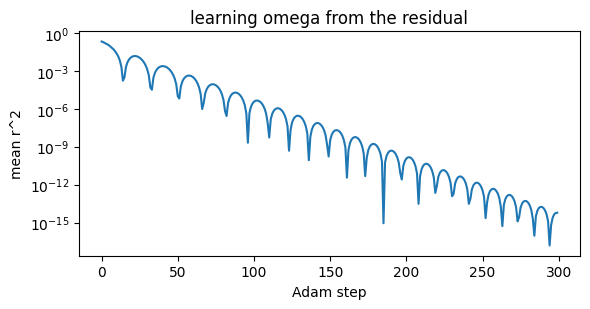

In [16]:
import torch
devices = ["cpu"] + (["cuda"] if torch.cuda.is_available() else [])
w0 = O.lc_params(L0, C0)["omega0"]
tg = np.linspace(0, 8 * math.pi / w0, 2000)
for d in devices:
    dev = O.torch_device(d)
    good = O.lc_residual(lambda tt: torch.cos(w0 * tt), L0, C0, tg, dev).abs().max().item()
    bad = O.lc_residual(lambda tt: torch.cos(1.1 * w0 * tt), L0, C0, tg, dev).abs().max().item()
    t0 = time.perf_counter(); fit = O.fit_omega(L0, C0, device=dev); dt = time.perf_counter() - t0
    print(f"{dev}: max|r| true = {good:.1e}, 10% off = {bad:.3f};  fit omega/omega0 = {fit['omega_fit']/w0:.6f} in {dt:.2f} s")
plt.figure(figsize=(6, 3.2)); plt.semilogy(fit["loss"]); plt.xlabel("Adam step"); plt.ylabel("mean r^2")
plt.title("learning omega from the residual"); plt.tight_layout(); plt.show()

## 7. Compile every Lean cell at once

`%lean_check` joins the cells in order and runs `lake env lean` once.

In [17]:
%%lean footer
end LCOsc

**Lean cell `footer`** (collected; compiled by `%lean_check`)
```lean
end LCOsc
```

In [18]:
lean_result = %lean_check
from dgs.lean_magic import SESSION
display(pd.DataFrame({"Lean theorem": SESSION.last.theorems, "status": SESSION.last.status}))

Lean status: VERIFIED  (lake env lean exit 0, no errors, no sorry), 49 s


,Lean theorem,status
0,energy_mapping,VERIFIED
1,energy_rate_zero,VERIFIED
2,hasDerivAt_cos_mul,VERIFIED
3,hasDerivAt_sin_mul,VERIFIED
4,cos_second_deriv,VERIFIED
5,lc_equation,VERIFIED
6,ladder_spacing,VERIFIED
7,zero_point_positive,VERIFIED
8,zero_point_product,VERIFIED
9,thz_wavelength_sub_mm,VERIFIED
